In [5]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
import gc
import os
from scipy import stats

In [2]:
train_transaction = pd.read_csv("../data/raw/train_transaction.csv")
train_identity = pd.read_csv("../data/raw/train_identity.csv")
test_transaction = pd.read_csv("../data/raw/test_transaction.csv")
test_identity = pd.read_csv("../data/raw/test_identity.csv")

In [3]:
train_transaction.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
train_identity.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [6]:
# Merge transaction and identity data on TransactionID
train = train_transaction.merge(train_identity, on='TransactionID', how='left')
test = test_transaction.merge(test_identity, on='TransactionID', how='left')

print(f"Train Shape after merge: {train.shape}")
print(f"Test Shape after merge: {test.shape}")

# Free memory
del train_transaction, test_transaction, train_identity, test_identity
gc.collect()

Train Shape after merge: (590540, 434)
Test Shape after merge: (506691, 433)


27

isFraud
0    569877
1     20663
Name: count, dtype: int64


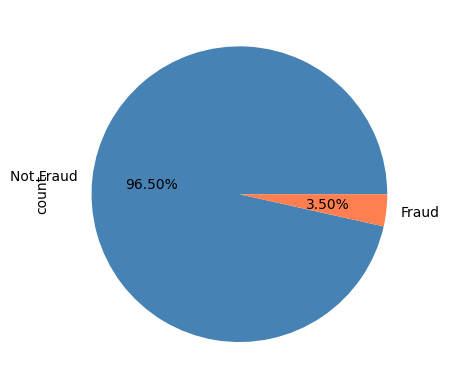

In [8]:
# Target distribution
print(train['isFraud'].value_counts())

# Visualize target distribution
train['isFraud'].value_counts().plot(kind='pie', autopct='%1.2f%%', 
                                     colors=['steelblue', 'coral'], labels=['Not Fraud', 'Fraud'])
plt.show()

In [9]:
# Column categories
print("\nColumn Categories:")
print(f"- C columns (counting): {[c for c in train.columns if c.startswith('C')]}")
print(f"- D columns (timedelta): {[c for c in train.columns if c.startswith('D')]}")
print(f"- M columns (match): {[c for c in train.columns if c.startswith('M')]}")
print(f"- V columns (Vesta features): {len([c for c in train.columns if c.startswith('V')])} columns")
print(f"- id columns: {[c for c in train.columns if c.startswith('id_')]}")


Column Categories:
- C columns (counting): ['C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14']
- D columns (timedelta): ['D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'DeviceType', 'DeviceInfo']
- M columns (match): ['M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']
- V columns (Vesta features): 339 columns
- id columns: ['id_01', 'id_02', 'id_03', 'id_04', 'id_05', 'id_06', 'id_07', 'id_08', 'id_09', 'id_10', 'id_11', 'id_12', 'id_13', 'id_14', 'id_15', 'id_16', 'id_17', 'id_18', 'id_19', 'id_20', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27', 'id_28', 'id_29', 'id_30', 'id_31', 'id_32', 'id_33', 'id_34', 'id_35', 'id_36', 'id_37', 'id_38']


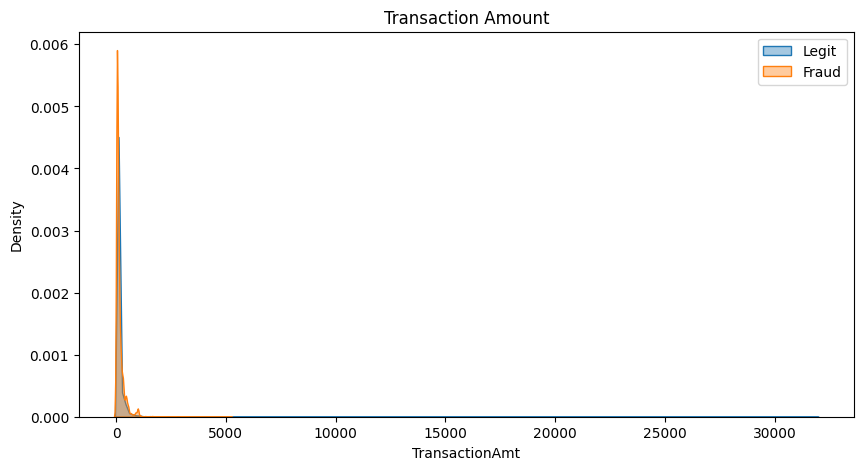

In [15]:
plt.figure(figsize=(10, 5))
sns.kdeplot(x=train['TransactionAmt'][train['isFraud'] == 0], label='Legit', fill=True, alpha=0.4)
sns.kdeplot(x=train['TransactionAmt'][train['isFraud'] == 1], label='Fraud', fill=True, alpha=0.4)
plt.title("Transaction Amount")
plt.legend()
plt.show()

Log Transformation (np.log1p): Financial data is extremely skewed (millions of $5 purchases, very few $5,000 purchases). Machine learning models struggle with this imbalance. Taking the log "squashes" the massive numbers down so the model isn't blinded by extreme outliers. The 1p just adds 1 to the amount before logging to prevent mathematical errors if a transaction is $0.

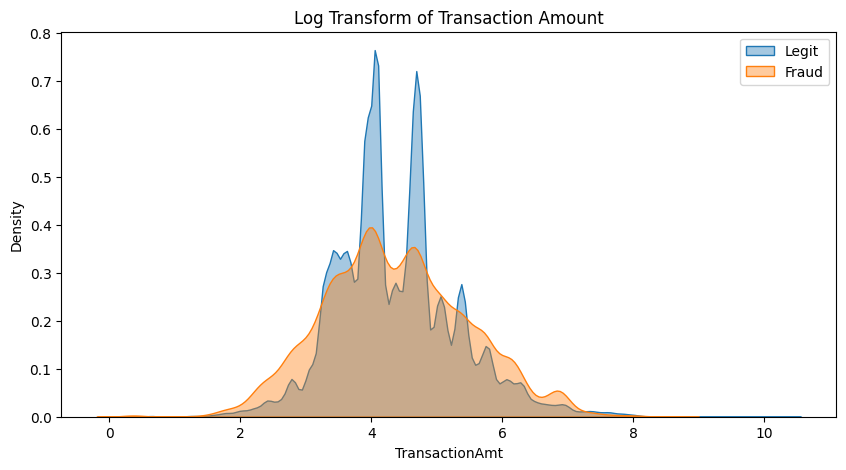

In [18]:
# Log transform TransactionAmt
temp_log = np.log1p(train['TransactionAmt'])

plt.figure(figsize=(10, 5))
sns.kdeplot(x=temp_log[train['isFraud'] == 0], label='Legit', fill=True, alpha=0.4)
sns.kdeplot(x=temp_log[train['isFraud'] == 1], label='Fraud', fill=True, alpha=0.4)
plt.title("Log Transform of Transaction Amount")
plt.legend()
plt.show()

Isolating the Cents: Normal shoppers frequently buy items priced by marketing psychology ($19.99 or $49.95). Fraudsters, on the other hand, often test stolen cards with clean, round numbers ($50.00) or run automated scripts that might generate bizarre decimal fractions.

In [17]:
# Calculation of cents
temp_cents = (train['TransactionAmt'] * 100).round() % 100

print("--- Fraud Rates by Cents ---")

# Is it a round number ($X.00)?
round_fraud_rate = train[temp_cents == 0]['isFraud'].mean() * 100
print(f"Round amounts (.00): {round_fraud_rate:.2f}% fraud")

# Does it end in typical retail numbers like .99 or .95?
retail_99_rate = train[temp_cents == 99]['isFraud'].mean() * 100
retail_95_rate = train[temp_cents == 95]['isFraud'].mean() * 100
print(f"Retail amounts (.99): {retail_99_rate:.2f}% fraud")
print(f"Retail amounts (.95): {retail_95_rate:.2f}% fraud")

# What about all other random decimal numbers?
weird_decimal_rate = train[~temp_cents.isin([0, 95, 99])]['isFraud'].mean() * 100
print(f"Random weird decimals: {weird_decimal_rate:.2f}% fraud")

--- Fraud Rates by Cents ---
Round amounts (.00): 3.59% fraud
Retail amounts (.99): 2.52% fraud
Retail amounts (.95): 0.75% fraud
Random weird decimals: 7.55% fraud


Binning (pd.cut): This groups continuous dollar amounts into specific buckets (e.g., $0-50 is bucket 0, $50-100 is bucket 1). Sometimes models learn patterns better from "small vs. large purchase" categories than from exact dollar values.

C:\Users\Anmoy\AppData\Local\Temp\ipykernel_31076\661833407.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fraud_by_bin = train.groupby(temp_bins)['isFraud'].mean() * 100


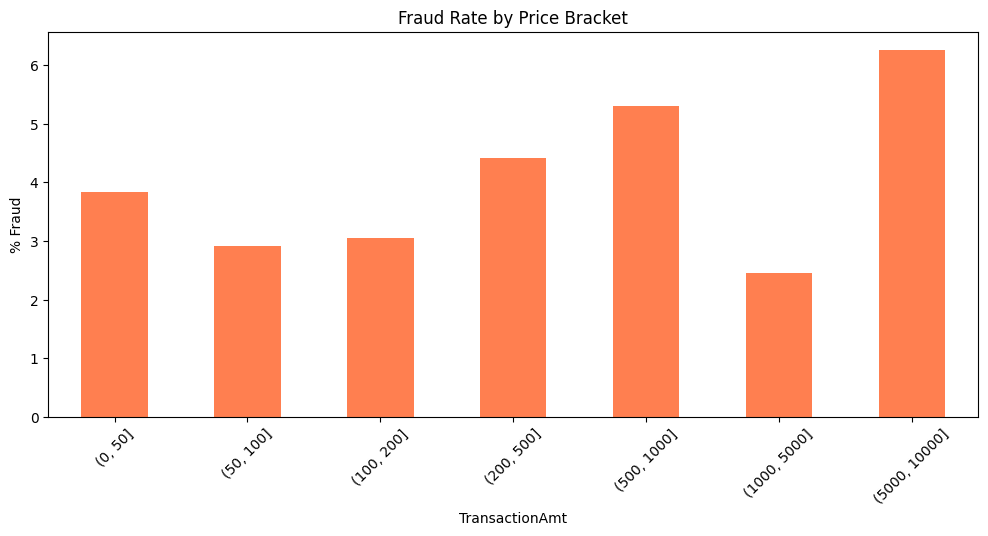

In [19]:
# Transaction Amount Binning
temp_bins = pd.cut(train['TransactionAmt'], 
                   bins=[0, 50, 100, 200, 500, 1000, 5000, 10000])

fraud_by_bin = train.groupby(temp_bins)['isFraud'].mean() * 100

plt.figure(figsize=(12, 5))
fraud_by_bin.plot(kind='bar', color='coral')
plt.title("Fraud Rate by Price Bracket")
plt.ylabel("% Fraud")
plt.xticks(rotation=45)
plt.show()

TransactionDT is a continuous counter of seconds from an unknown start date. We need to convert these seconds into hours and days to see if fraud spikes at specific times.

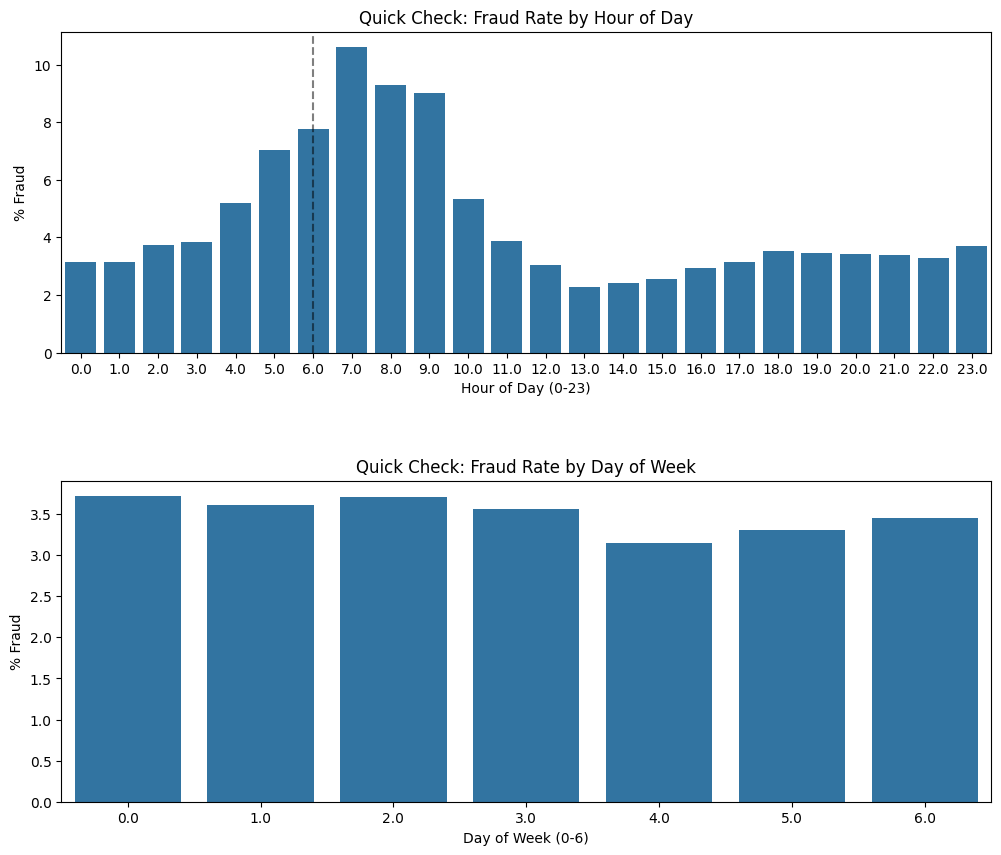

In [21]:
# Time columns
temp_hour = np.floor(train['TransactionDT'] / 3600) % 24
temp_dow = np.floor(train['TransactionDT'] / (3600 * 24)) % 7

fig, axes = plt.subplots(2, 1, figsize=(12, 10))
plt.subplots_adjust(hspace=0.4)

# Plot 1: Is there a "Witching Hour" for fraud?
hour_fraud = train.groupby(temp_hour)['isFraud'].mean() * 100
sns.barplot(x=hour_fraud.index, y=hour_fraud.values, ax=axes[0])
axes[0].set_title('Quick Check: Fraud Rate by Hour of Day')
axes[0].set_xlabel('Hour of Day (0-23)')
axes[0].set_ylabel('% Fraud')
axes[0].axvline(6, color='black', linestyle='--', alpha=0.5)

# Plot 2: Does fraud change depending on the day of the week?
dow_fraud = train.groupby(temp_dow)['isFraud'].mean() * 100
sns.barplot(x=dow_fraud.index, y=dow_fraud.values, ax=axes[1])
axes[1].set_title('Quick Check: Fraud Rate by Day of Week')
axes[1].set_xlabel('Day of Week (0-6)')
axes[1].set_ylabel('% Fraud')

plt.show()

# Card

In [23]:
train["card4"].value_counts()

card4
visa                384767
mastercard          189217
american express      8328
discover              6651
Name: count, dtype: int64

In [24]:
train["card6"].value_counts()

card6
debit              439938
credit             148986
debit or credit        30
charge card            15
Name: count, dtype: int64

Because credit card datasets are anonymized to protect privacy, we can't track a specific person's behavior. Instead, data scientists create "proxy IDs" by combining features. For example, card1 (the bank) + addr1 (the billing zip code) + Transaction_hour creates a highly specific behavioral fingerprint. If this specific fingerprint suddenly buys an expensive item (ProductCD) from a new zip code, it signals an account takeover.

In [22]:
# 1. Look at Card Type and Card Category
print("--- Fraud Rates by Single Features ---")
print(train.groupby('card4')['isFraud'].mean() * 100)
print("\n")
print(train.groupby('card6')['isFraud'].mean() * 100)

--- Fraud Rates by Single Features ---
card4
american express    2.869837
discover            7.728161
mastercard          3.433095
visa                3.475610
Name: isFraud, dtype: float64


card6
charge card        0.000000
credit             6.678480
debit              2.426251
debit or credit    0.000000
Name: isFraud, dtype: float64


In [26]:
# 2. the Interaction of card4 and card6
print("--- Fraud Rates by Combined Features ---")
temp_combo = train['card4'].astype(str) + '_' + train['card6'].astype(str)
combo_rates = train.groupby(temp_combo)['isFraud'].mean() * 100
print(combo_rates.sort_values(ascending=False))

--- Fraud Rates by Combined Features ---
nan_credit                      33.333333
nan_debit                       11.111111
discover_credit                  7.931472
mastercard_credit                6.915229
visa_credit                      6.812210
discover_debit                   4.034582
american express_debit           3.472222
american express_credit          2.862385
visa_debit                       2.547646
nan_nan                          2.492013
mastercard_debit                 2.156558
american express_nan             0.000000
american express_charge card     0.000000
mastercard_debit or credit       0.000000
visa_charge card                 0.000000
Name: isFraud, dtype: float64


In [28]:
train['card1'].value_counts()

card1
7919     14932
9500     14162
15885    10361
17188    10344
15066     7945
         ...  
7914         1
15126        1
2570         1
9115         1
1099         1
Name: count, Length: 13553, dtype: int64

In [29]:
train['ProductCD'].value_counts()

ProductCD
W    439670
C     68519
R     37699
H     33024
S     11628
Name: count, dtype: int64

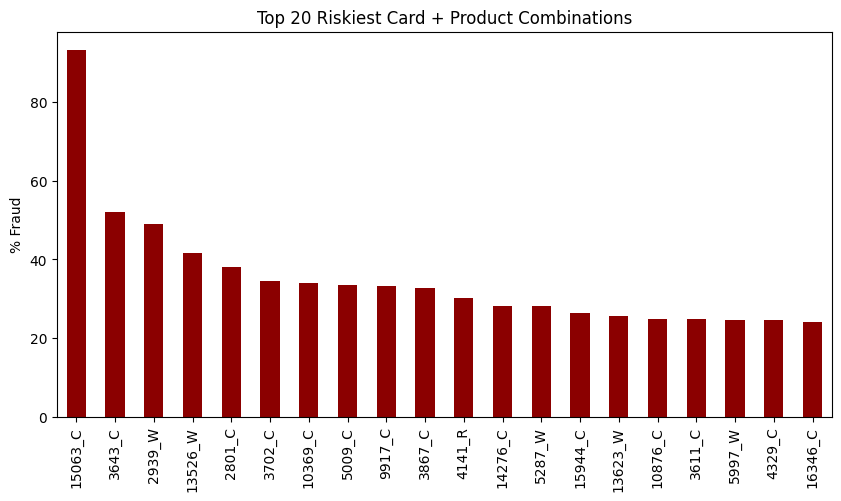

In [27]:
# 3. Visualizing the power of combinations
# Does combining a card with a specific product reveal higher risk?
temp_card_prod = train['card1'].astype(str) + '_' + train['ProductCD'].astype(str)

# Calculate fraud rate for combinations that occur at least 100 times (to filter noise)
combo_counts = temp_card_prod.value_counts()
valid_combos = combo_counts[combo_counts > 100].index
filtered_rates = train[temp_card_prod.isin(valid_combos)].groupby(temp_card_prod)['isFraud'].mean() * 100

plt.figure(figsize=(10, 5))
# Plot the top 20 riskiest combinations
filtered_rates.sort_values(ascending=False).head(20).plot(kind='bar', color='darkred')
plt.title('Top 20 Riskiest Card + Product Combinations')
plt.ylabel('% Fraud')
plt.xticks(rotation=90)
plt.show()

In fraud detection, emails are a massive leak of intent. Fraudsters rarely have access to a victim's actual corporate email, so they default to free, disposable providers. More importantly, this dataset has two emails: Purchaser (the person paying) and Recipient (the person receiving). If a fraudster steals a card, they might use the victim's email for the billing (P), but their own email to receive the digital goods or shipping confirmation (R).

In [30]:
# 1. Free vs. Business/Niche Providers
temp_prefix = train['P_emaildomain'].str.split('.').str[0]
common = ['gmail', 'yahoo', 'hotmail', 'outlook', 'aol', 'icloud', 'live', 'msn']
temp_is_common = temp_prefix.isin(common)

print("--- Fraud by Email Provider Type ---")
print(f"Common Free Email: {train[temp_is_common]['isFraud'].mean() * 100:.2f}%")
print(f"Business/Niche Email: {train[~temp_is_common]['isFraud'].mean() * 100:.2f}%")

--- Fraud by Email Provider Type ---
Common Free Email: 3.82%
Business/Niche Email: 2.67%


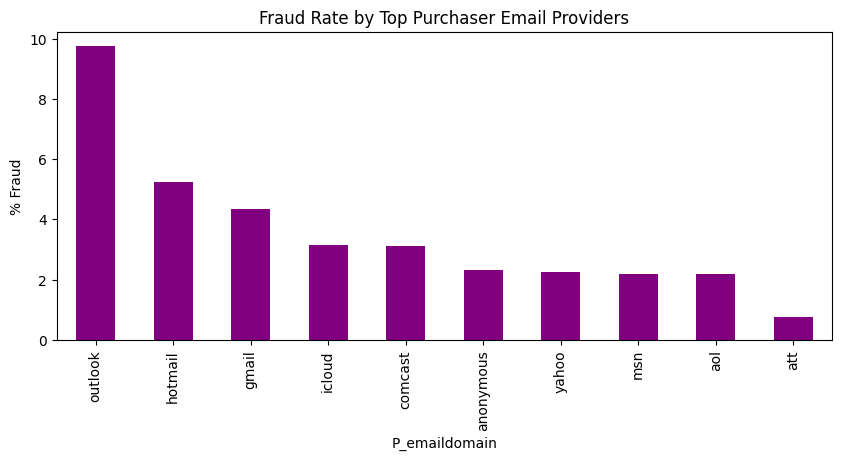

In [31]:
# 2. Top Email Providers Fraud Rate
top_emails = temp_prefix.value_counts().head(10).index
email_fraud = train[temp_prefix.isin(top_emails)].groupby(temp_prefix)['isFraud'].mean() * 100

plt.figure(figsize=(10, 4))
email_fraud.sort_values(ascending=False).plot(kind='bar', color='purple')
plt.title('Fraud Rate by Top Purchaser Email Providers')
plt.ylabel('% Fraud')
plt.show()

In [32]:
# 3. The P and R Mismatch
# Is it riskier when the Purchaser and Recipient emails don't match?
temp_match = (train['P_emaildomain'] == train['R_emaildomain'])
# Exclude rows where both are null for a fair comparison
valid_pairs = train.dropna(subset=['P_emaildomain', 'R_emaildomain'])
match_fraud = valid_pairs.groupby(valid_pairs['P_emaildomain'] == valid_pairs['R_emaildomain'])['isFraud'].mean() * 100

print("\n--- Fraud by Email Match ---")
print(f"Emails Match: {match_fraud[True]:.2f}%")
print(f"Emails MISMATCH: {match_fraud[False]:.2f}%")


--- Fraud by Email Match ---
Emails Match: 9.65%
Emails MISMATCH: 2.87%


Fraudsters often run automated botnets on virtual machines, headless browsers, or specific operating systems that are easier to script (like Windows or Android, compared to iOS). Sometimes, the "fingerprint" of a device is the clearest giveaway—for example, if a user is trying to make a massive purchase on a tiny 800x600 screen, it might be a bot script running in a cheap virtual environment.

In [35]:
# 1. Mobile vs Desktop
print("--- Fraud by Device Type ---")
if 'DeviceType' in train.columns:
    print(train.groupby('DeviceType')['isFraud'].mean() * 100)

--- Fraud by Device Type ---
DeviceType
desktop     6.521458
mobile     10.166232
Name: isFraud, dtype: float64


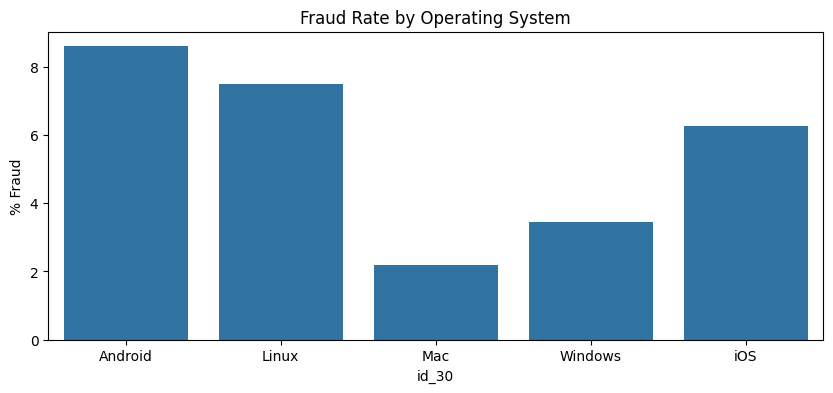

In [36]:
# 2. Operating System Risk (id_30)
if 'id_30' in train.columns:
    # Extract just the first word of the OS (e.g., "Windows 10" -> "Windows")
    temp_os = train['id_30'].str.split().str[0]
    
    # Filter to top 5 OS types to remove noise
    top_os = temp_os.value_counts().head(5).index
    os_fraud = train[temp_os.isin(top_os)].groupby(temp_os)['isFraud'].mean() * 100
    
    plt.figure(figsize=(10, 4))
    sns.barplot(x=os_fraud.index, y=os_fraud.values)
    plt.title('Fraud Rate by Operating System')
    plt.ylabel('% Fraud')
    plt.show()

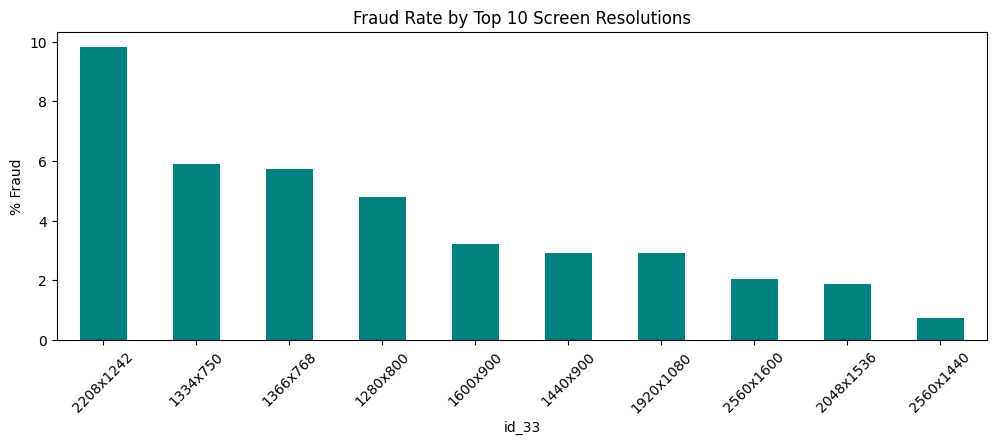

In [37]:
# 3. Screen Resolution Anomalies (id_33)
if 'id_33' in train.columns:
    # Look at the fraud rate for the 10 most common screen resolutions
    top_screens = train['id_33'].value_counts().head(10).index
    screen_fraud = train[train['id_33'].isin(top_screens)].groupby('id_33')['isFraud'].mean() * 100
    
    plt.figure(figsize=(12, 4))
    screen_fraud.sort_values(ascending=False).plot(kind='bar', color='teal')
    plt.title('Fraud Rate by Top 10 Screen Resolutions')
    plt.ylabel('% Fraud')
    plt.xticks(rotation=45)
    plt.show()

addr1 roughly correlates to the billing region or zip code, and addr2 is the billing country. dist1 and dist2 are distances (e.g., the physical distance between the billing address and the IP address making the purchase).

Missing data is rarely random. Fraudsters often use VPNs, proxies, or guest checkouts that intentionally obscure location data. Therefore, the absence of a distance or address is often a massive red flag.

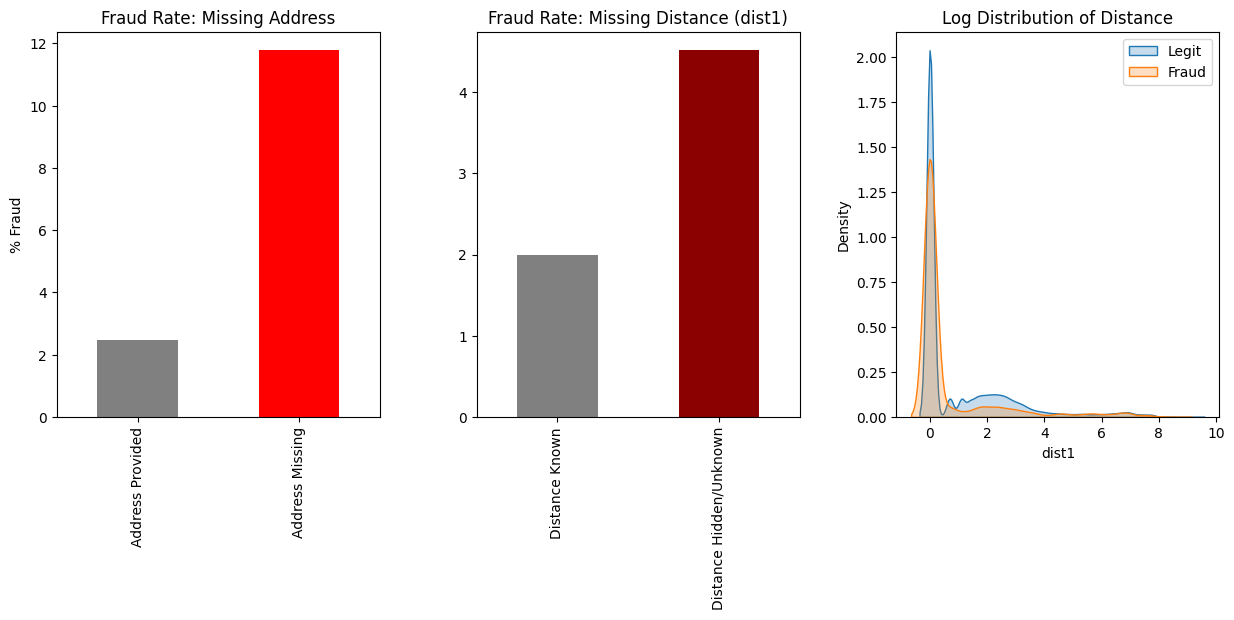

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
plt.subplots_adjust(wspace=0.3)

# 1. Does a missing Address mean higher risk?
missing_addr_fraud = pd.Series({
    'Address Provided': train[train['addr1'].notna()]['isFraud'].mean() * 100,
    'Address Missing': train[train['addr1'].isna()]['isFraud'].mean() * 100
})
missing_addr_fraud.plot(kind='bar', ax=axes[0], color=['gray', 'red'])
axes[0].set_title('Fraud Rate: Missing Address')
axes[0].set_ylabel('% Fraud')

# 2. Does a missing Distance (dist1) mean higher risk?
if 'dist1' in train.columns:
    missing_dist_fraud = pd.Series({
        'Distance Known': train[train['dist1'].notna()]['isFraud'].mean() * 100,
        'Distance Hidden/Unknown': train[train['dist1'].isna()]['isFraud'].mean() * 100
    })
    missing_dist_fraud.plot(kind='bar', ax=axes[1], color=['gray', 'darkred'])
    axes[1].set_title('Fraud Rate: Missing Distance (dist1)')

# 3. Why log transform the distance?
if 'dist1' in train.columns:
    # Fill NA with 0 temporarily just to see the distribution
    temp_dist_log = np.log1p(train['dist1'].fillna(0))
    
    sns.kdeplot(x=temp_dist_log[train['isFraud'] == 0], label='Legit', fill=True, ax=axes[2])
    sns.kdeplot(x=temp_dist_log[train['isFraud'] == 1], label='Fraud', fill=True, ax=axes[2])
    axes[2].set_title('Log Distribution of Distance')
    axes[2].legend()

plt.show()

The V-columns (V1 through V339) are Vesta Corporation's proprietary, anonymized features. They are incredibly powerful, but there are 339 of them—feeding all of them into a model causes massive overfitting

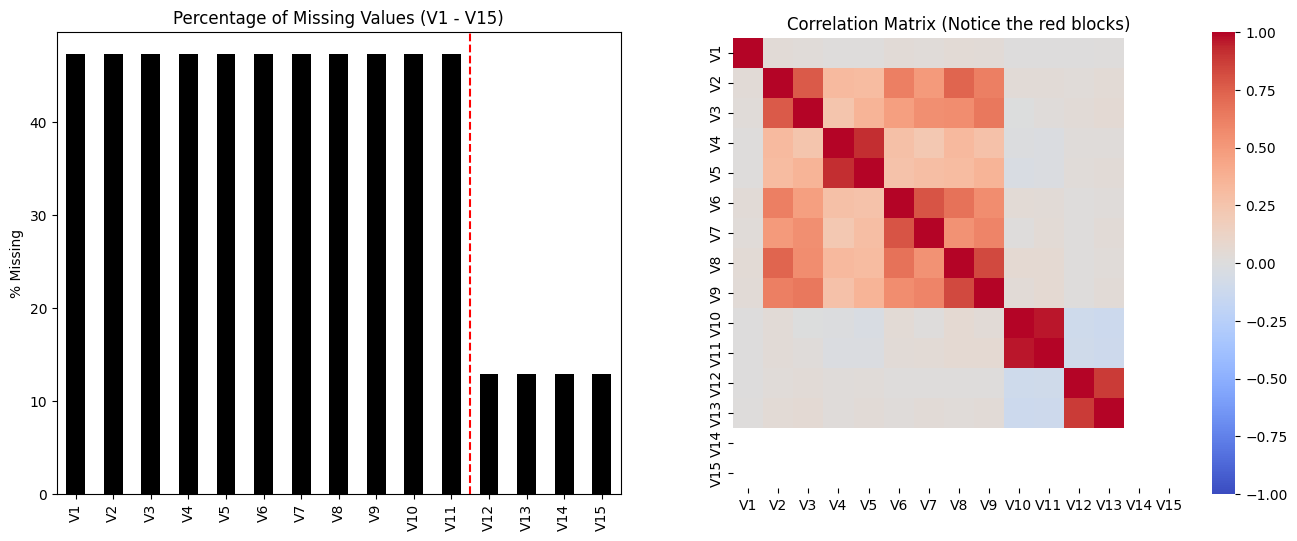

In [39]:
# We will just look at V1 through V15 to prove the concept
v_sample = [f'V{i}' for i in range(1, 16)]

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. The Missing Value Pattern (The NaN Blocks)
# Notice how V1-V11 have the exact same number of missing values!
nan_counts = train[v_sample].isna().mean() * 100
nan_counts.plot(kind='bar', ax=axes[0], color='black')
axes[0].set_title('Percentage of Missing Values (V1 - V15)')
axes[0].set_ylabel('% Missing')
axes[0].axvline(10.5, color='red', linestyle='--') # The boundary between Block 1 and Block 2

# 2. The Correlation Matrix
# We calculate correlation on a sample to speed it up
corr_matrix = train[v_sample].dropna().corr()
sns.heatmap(corr_matrix, ax=axes[1], cmap='coolwarm', vmin=-1, vmax=1, 
            annot=False, square=True)
axes[1].set_title('Correlation Matrix (Notice the red blocks)')

plt.show()

When dealing with hundreds of columns, a correlation heatmap becomes an unreadable blur. Vesta clearly built these features in distinct modules (e.g., an "email tracking" module, a "billing address" module). If a transaction is missing email data, every single column associated with that module becomes NaN at the exact same time.

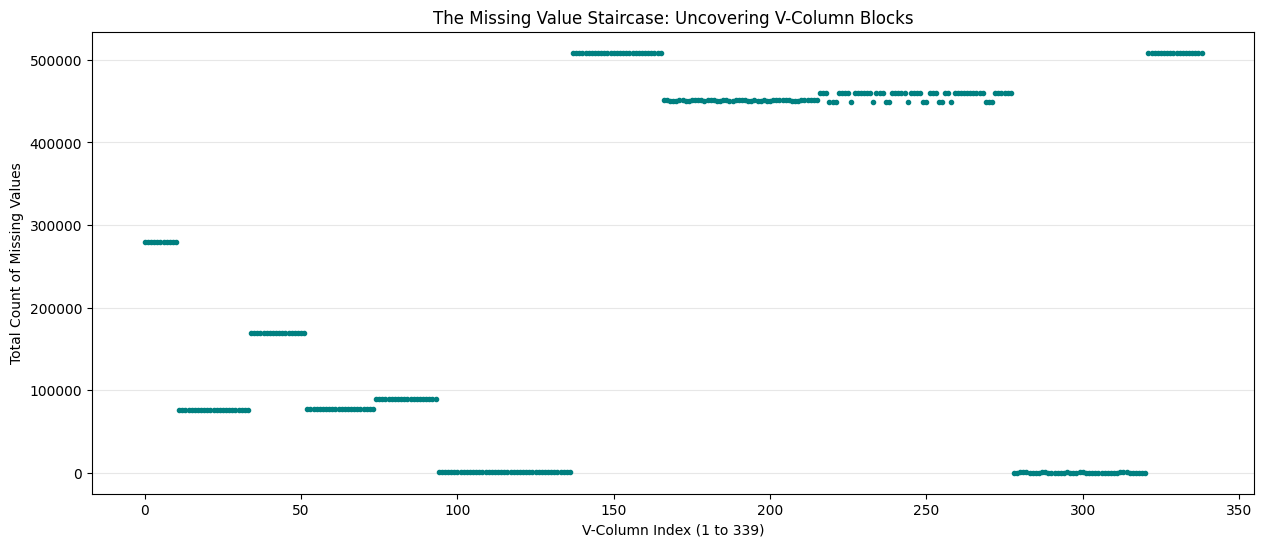

--- Automatically Discovered V-Blocks ---
Block with 279287 missing values: V1 to V11 (11 columns)
Block with 76073 missing values: V12 to V34 (23 columns)
Block with 168969 missing values: V35 to V52 (18 columns)
Block with 77096 missing values: V53 to V74 (22 columns)
Block with 89164 missing values: V75 to V94 (20 columns)
Block with 314 missing values: V95 to V137 (43 columns)
Block with 508595 missing values: V138 to V163 (18 columns)
Block with 508589 missing values: V143 to V166 (11 columns)
Block with 450909 missing values: V167 to V216 (31 columns)
Block with 450721 missing values: V169 to V210 (19 columns)
Block with 460110 missing values: V217 to V278 (46 columns)
Block with 449124 missing values: V220 to V272 (16 columns)
Block with 12 missing values: V279 to V321 (32 columns)
Block with 1269 missing values: V281 to V315 (11 columns)
Block with 508189 missing values: V322 to V339 (18 columns)


In [40]:
# Grab every single V column in the dataset
all_v_cols = [c for c in train.columns if c.startswith('V')]

# Calculate the exact number of missing values for each column
missing_counts = train[all_v_cols].isna().sum()

plt.figure(figsize=(15, 6))
# A line plot makes it easy to see the "plateaus" where missing values are identical
plt.plot(range(len(all_v_cols)), missing_counts.values, marker='.', linestyle='none', color='teal')

plt.title('The Missing Value Staircase: Uncovering V-Column Blocks')
plt.xlabel('V-Column Index (1 to 339)')
plt.ylabel('Total Count of Missing Values')
plt.grid(axis='y', alpha=0.3)
plt.show()

# To programmatically extract the exact column names in each block:
from collections import defaultdict

# Group columns that have the exact same number of missing values
v_blocks = defaultdict(list)
for col, missing_val in missing_counts.items():
    v_blocks[missing_val].append(col)

# Print the groups that have more than 5 columns
print("--- Automatically Discovered V-Blocks ---")
for missing_count, cols in v_blocks.items():
    if len(cols) > 5:
        print(f"Block with {missing_count} missing values: {cols[0]} to {cols[-1]} ({len(cols)} columns)")

The C columns are counts (e.g., how many times this email was used, how many addresses are linked to this card). They are notoriously skewed—most users have a count of 1 or 2, but fraudsters running automated scripts might have a count of 400.

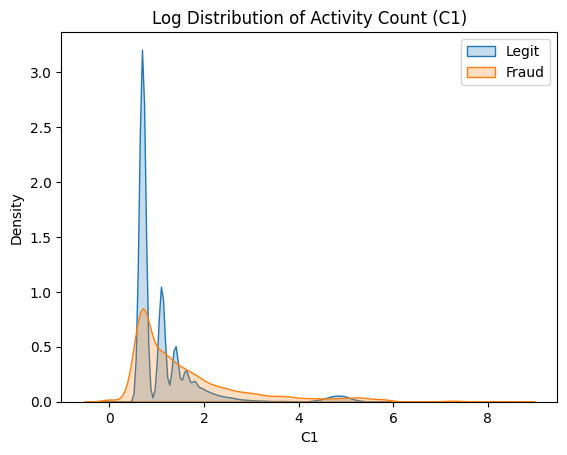

In [43]:
# 1. The Skewness of Counts (Why C needs a Log Transform)
if 'C1' in train.columns:
    # Most legit users have low counts. Bots have massive counts.
    # The Log transform squashes the bot activity down so the model can read it.
    temp_c_log = np.log1p(train['C1'])
    sns.kdeplot(x=temp_c_log[train['isFraud'] == 0], label='Legit', fill=True)
    sns.kdeplot(x=temp_c_log[train['isFraud'] == 1], label='Fraud', fill=True)
    plt.title('Log Distribution of Activity Count (C1)')
    plt.legend()
    plt.show()

The D columns are time-deltas (e.g., days since the card was first used, days since the last transaction). Just like the address features, a missing time-delta usually means this is a brand new account or a guest checkout, which inherently carries higher risk.

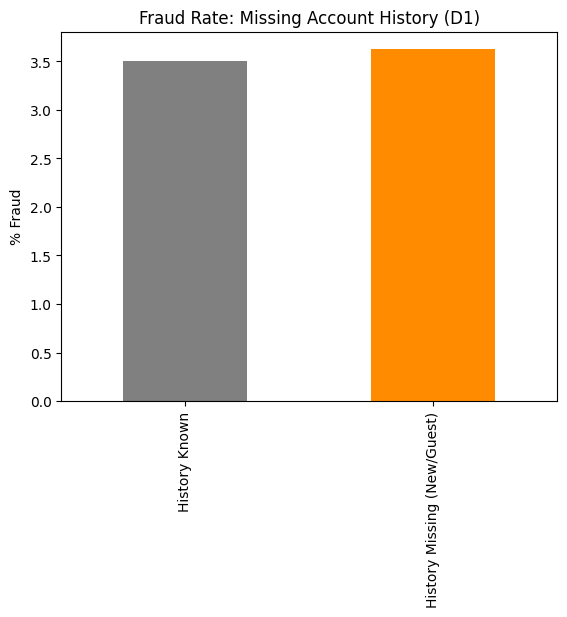

In [44]:
# 2. The Danger of Unknown History (Why missing D matters)
if 'D1' in train.columns:
    # D1 is usually "days since card was first registered/used"
    d1_missing_fraud = pd.Series({
        'History Known': train[train['D1'].notna()]['isFraud'].mean() * 100,
        'History Missing (New/Guest)': train[train['D1'].isna()]['isFraud'].mean() * 100
    })
    d1_missing_fraud.plot(kind='bar', color=['gray', 'darkorange'])
    plt.title('Fraud Rate: Missing Account History (D1)')
    plt.ylabel('% Fraud')
    plt.show()

The M columns (Match features) indicate whether the details provided during the transaction (like names, addresses, or phone numbers) match what the bank has on file. In fraud, a mismatch ('F') or a missing value ('NaN') is often a massive red flag indicating the fraudster doesn't have the victim's complete profile.

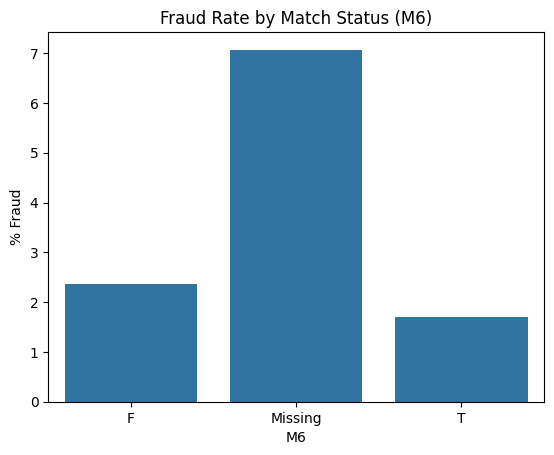

In [45]:
# 1. Look at a single Match column (e.g., M6)
if 'M6' in train.columns:
    # Fill NaN so we can plot it as a distinct category
    temp_m6 = train['M6'].fillna('Missing')
    m6_fraud = train.groupby(temp_m6)['isFraud'].mean() * 100
    
    sns.barplot(x=m6_fraud.index, y=m6_fraud.values)
    plt.title('Fraud Rate by Match Status (M6)')
    plt.ylabel('% Fraud')
    plt.show()

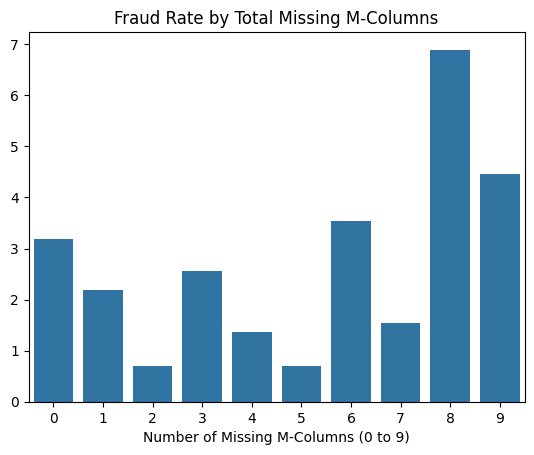

In [46]:
# 2. Look at the aggregate (Total missing match features)
m_cols = ['M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9']
existing_m = [c for c in m_cols if c in train.columns]

if existing_m:
    temp_missing_count = train[existing_m].isna().sum(axis=1)
    missing_agg_fraud = train.groupby(temp_missing_count)['isFraud'].mean() * 100
    
    sns.barplot(x=missing_agg_fraud.index, y=missing_agg_fraud.values)
    plt.title('Fraud Rate by Total Missing M-Columns')
    plt.xlabel('Number of Missing M-Columns (0 to 9)')
    plt.show()

Frequency: Is this a rare entity? (Fraudsters often use newly generated emails or burner devices that only appear once).

Deviation: Is this transaction anomalous for this specific card? (A $500 purchase is normal for a black card, but highly suspicious for a student debit card).

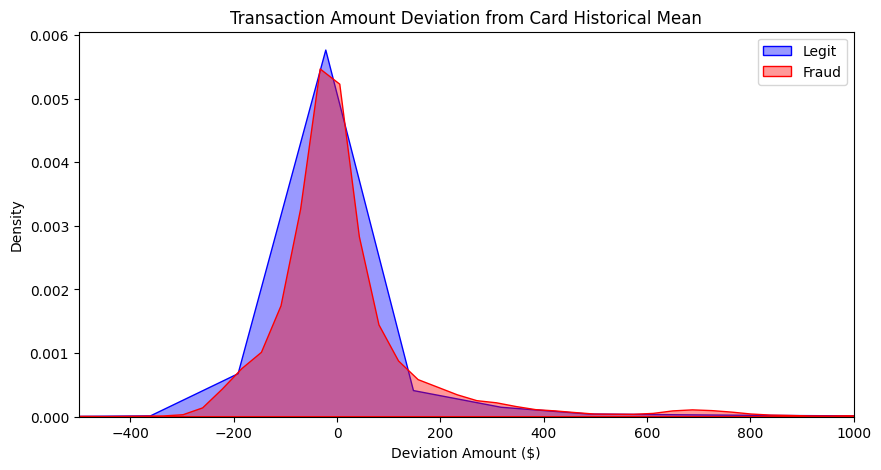

In [47]:
# 1. Calculate the historical mean for each card (Train data only!)
card_means = train.groupby('card1')['TransactionAmt'].mean()

# 2. Map it back to the transactions
temp_card_mean = train['card1'].map(card_means)

# 3. Calculate how far this transaction deviates from the card's usual behavior
temp_deviation = train['TransactionAmt'] - temp_card_mean

# 4. Plot the deviations
plt.figure(figsize=(10, 5))
sns.kdeplot(x=temp_deviation[train['isFraud'] == 0], label='Legit', fill=True, alpha=0.4, color='blue')
sns.kdeplot(x=temp_deviation[train['isFraud'] == 1], label='Fraud', fill=True, alpha=0.4, color='red')
plt.title('Transaction Amount Deviation from Card Historical Mean')
plt.xlim(-500, 1000) # Zoom in to see the split
plt.xlabel('Deviation Amount ($)')
plt.legend()
plt.show()

The id columns in the IEEE dataset represent network and device connection details (like IP matching, proxy statuses, and previous account associations). Because Vesta only collects this deep identity data when a transaction triggers a risk check or 3D-Secure, nearly 75% of the dataset is missing this information entirely.

Therefore, simply knowing whether an ID is "New", "Found" (in the database), or "Missing" is a massive indicator of fraud.

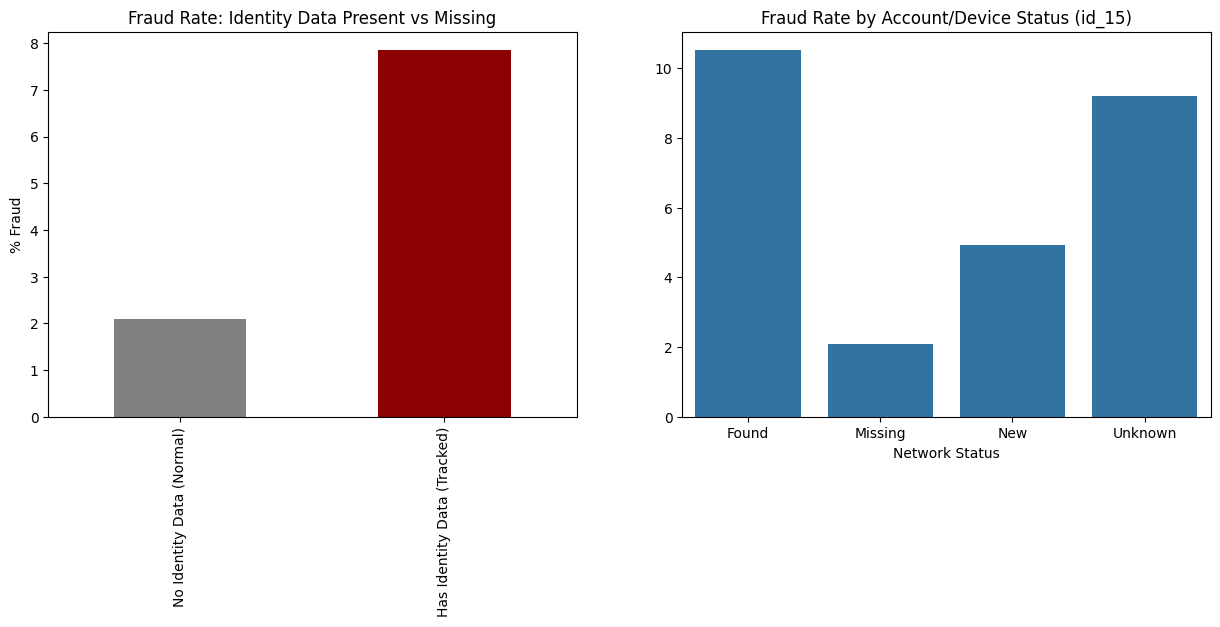

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. The inherent risk of Identity Data existing at all
# Does having identity data mean the transaction is riskier?
has_id_fraud = pd.Series({
    'No Identity Data (Normal)': train[train['id_01'].isna()]['isFraud'].mean() * 100,
    'Has Identity Data (Tracked)': train[train['id_01'].notna()]['isFraud'].mean() * 100
})
has_id_fraud.plot(kind='bar', ax=axes[0], color=['gray', 'darkred'])
axes[0].set_title('Fraud Rate: Identity Data Present vs Missing')
axes[0].set_ylabel('% Fraud')

# 2. "Found" (Returning User) vs "New" (Potential Burner/Fraudster)
if 'id_15' in train.columns:
    # id_15 typically represents whether the device/account linkage is New or Found
    temp_id15 = train['id_15'].fillna('Missing')
    id15_fraud = train.groupby(temp_id15)['isFraud'].mean() * 100
    
    sns.barplot(x=id15_fraud.index, y=id15_fraud.values, ax=axes[1])
    axes[1].set_title('Fraud Rate by Account/Device Status (id_15)')
    axes[1].set_xlabel('Network Status')

plt.show()